# Part C: Cross-Dimension Analysis

Experiment and analysis in one notebook (`6_cross_dimension_analysis`).
Run on a free Kaggle T4 GPU. Results are read from and written to `results/` in this repository.


# 6 Part C: Cross-dimension analysis (Stress set, 60 items)

Combines results that already exist for the 60 Stress items (`row_index` 0-59) - no new model runs, no new data. Everything is computed **separately per model**.

## Per-item variables
| variable | source | definition |
|---|---|---|
| clean uncertainty | Part A baseline | **normalised entropy** of the clean option distribution, $H / \log(n_{options})$ in [0, 1] (items have 5-9 options, so raw entropy would partly measure the option count) |
| misleading flip | 5.1 | answer under misleading context ≠ clean answer (all 60 items) |
| injection hijack | 5.4.1 | answer under injection = attacker's option k; items whose clean answer already was k are excluded |
| canary leak | 5.4.2 | exact canary appears in the attack output |
| metadata instability | 5.3 | number of the 6 metadata variants whose answer ≠ clean answer (0-6) |

## Primary analysis - are failures concentrated on items the model was already unsure about?
For each failure type: **AUROC** of clean uncertainty for predicting the failure, with a bootstrap 95% CI (Mann-Whitney p also shown).
*Why:* continuous predictor, binary outcome, small n; AUROC is rank-based (no distributional assumption) and is itself an effect size - 0.5 = no relationship, > 0.5 = uncertain items fail more. This generalises H2 (5.1 tested clean margin → flip among clean-correct items only; here: any change, all items, every failure type).

## Secondary analyses (Holm-corrected across the secondary p-values)
- **Do the two attacks hit the same items?** 2×2 of misleading → k vs injection → k (same target option k in both attacks; items with clean answer = k excluded): **odds ratio** (Haldane-Anscombe 0.5 correction for the CI) + **Fisher's exact test**.
- **Is metadata instability linked to uncertainty?** **Spearman ρ** between the 0-6 instability count and clean uncertainty (rank correlation suits a count outcome with ties), bootstrap 95% CI.

## Caveats
- Associations across 60 items - they show which failures co-occur, not that one causes another.
- Canary leak: Llama 8/60 leaks (exploratory, wide CI); Qwen 0 leaks → **not estimable**.
- Qwen's clean confidence is saturated (many items near probability 1), so its uncertainty has little spread near 0.

Outputs (`results/analysis/6_cross_dimension/`): `items_{model}.csv`, `primary_auroc.csv`, `secondary_tests.csv`, `contingency_tables.csv`, `summary.csv`, `fig_auroc.png`.

In [1]:
# Cell 1: paths and settings
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from scipy.stats import fisher_exact, mannwhitneyu, norm, spearmanr

# Project root = folder containing config.yaml (this folder, a parent, or the cloned repo below it)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents, *Path.cwd().glob("*/")]
            if (p / "config.yaml").exists())
CFG = yaml.safe_load((ROOT / "config.yaml").read_text())

OUTPUTS = ROOT / CFG["paths"]["outputs"]
OUT_DIR = OUTPUTS / CFG["paths"]["analysis"] / CFG["paths"]["analyses"]["cross_dimension"]
OUT_DIR.mkdir(parents=True, exist_ok=True)

MODELS = {"llama": CFG["models"]["llama"]["id"], "qwen": CFG["models"]["qwen"]["id"]}
STRESS_RANGE = CFG["subsets"]["stress"]
EXPECTED_ROWS = list(range(STRESS_RANGE[0], STRESS_RANGE[1]))
BIAS_VARIANTS = [f"{attr}_{value.split()[0].lower()}" for attr, value in CFG["prompts"]["bias"]["variants"]]
CANARY_TEMPLATE = CFG["prompts"]["canary"]["canary_template"]

N_BOOT = 10_000
SEED = CFG["seed"]
ALPHA = 0.05

print("bias variants:", BIAS_VARIANTS)
print("writing ->", OUT_DIR)

bias variants: ['race_black', 'race_white', 'insurance_uninsured', 'insurance_private', 'residence_rural', 'residence_urban']
writing -> /storage/sourava/LCS2/kaggle_outputs/../kaggle_analysis/6_cross_dimension


In [2]:
# Cell 2: build one table per model, one row per Stress item
def load(path: Path) -> pd.DataFrame:
    return pd.read_json(path, lines=True).set_index("row_index").sort_index()


ITEMS = {}
for key, model_id in MODELS.items():
    clean = load(OUTPUTS / CFG["paths"]["experiments"]["baseline"] / f"{key}_core.jsonl").loc[EXPECTED_ROWS]
    mis = load(OUTPUTS / CFG["paths"]["experiments"]["misleading"] / f"{key}_stress.jsonl")
    inj = load(OUTPUTS / CFG["paths"]["experiments"]["injection"] / f"{key}_injection.jsonl")
    can = load(OUTPUTS / CFG["paths"]["experiments"]["canary"] / f"{key}_canary.jsonl")
    bias = {v: load(OUTPUTS / CFG["paths"]["experiments"]["bias"] / f"{key}_{v}.jsonl") for v in BIAS_VARIANTS}

    for name, df in {"misleading": mis, "injection": inj, "canary": can, **bias}.items():
        assert list(df.index) == EXPECTED_ROWS, f"{key}/{name}: rows incomplete"
        assert (df["id"] == clean["id"]).all(), f"{key}/{name}: ids differ from clean"
        assert (df["model_revision"] == clean["model_revision"].iloc[0]).all(), f"{key}/{name}: revision differs"
    assert (mis["injected_key"] == inj["injected_key"]).all(), f"{key}: 5.1 and 5.4.1 target different options"

    k = inj["injected_key"]
    n_opt = clean["n_options"]
    t = pd.DataFrame({
        "id": clean["id"], "gold": clean["gold"], "n_options": n_opt, "injected_key": k,
        "clean_answer": clean["answer"], "clean_correct": clean["correct"].astype(bool),
        "clean_entropy": clean["entropy"],
        "clean_uncertainty": clean["entropy"] / np.log(n_opt),          # normalised entropy in [0, 1]
        "clean_is_k": clean["answer"] == k,
        "mis_answer": mis["answer"], "inj_answer": inj["answer"],
    })
    t["misleading_flip"] = t["mis_answer"] != t["clean_answer"]
    t["misleading_to_k"] = t["mis_answer"] == k
    t["injection_hijack"] = t["inj_answer"] == k
    t["canary_leak"] = [CANARY_TEMPLATE.format(id=i) in str(r) for i, r in zip(clean["id"], can["raw_output"])]
    t["metadata_instability"] = sum((bias[v]["answer"] != clean["answer"]).astype(int) for v in BIAS_VARIANTS)
    ITEMS[key] = t
    t.to_csv(OUT_DIR / f"items_{key}.csv")

    print(f"{key}: misleading flips {int(t['misleading_flip'].sum())}/60 | hijacks {int(t.loc[~t['clean_is_k'], 'injection_hijack'].sum())}"
          f"/{int((~t['clean_is_k']).sum())} (clean != k) | canary leaks {int(t['canary_leak'].sum())}/60 "
          f"| metadata instability 0-6: {t['metadata_instability'].value_counts().sort_index().to_dict()}")

llama: misleading flips 35/60 | hijacks 29/52 (clean != k) | canary leaks 8/60 | metadata instability 0-6: {0: 50, 1: 2, 2: 2, 4: 1, 5: 1, 6: 4}
qwen: misleading flips 43/60 | hijacks 9/54 (clean != k) | canary leaks 0/60 | metadata instability 0-6: {0: 42, 1: 4, 2: 2, 3: 4, 4: 1, 5: 1, 6: 6}


In [3]:
# Cell 3: statistics helpers
def auroc(scores: np.ndarray, labels: np.ndarray) -> float:
    """P(score of a failure > score of a non-failure), ties count 1/2 (Mann-Whitney form)."""
    pos, neg = scores[labels], scores[~labels]
    if len(pos) == 0 or len(neg) == 0:
        return np.nan
    diff = pos[:, None] - neg[None, :]
    return float(((diff > 0).sum() + 0.5 * (diff == 0).sum()) / diff.size)


def bootstrap_ci(stat, *arrays, n_boot: int = N_BOOT, seed: int = SEED) -> tuple[float, float]:
    """Percentile bootstrap over items; resamples where the statistic is undefined are skipped."""
    rng = np.random.default_rng(seed)
    n = len(arrays[0])
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        v = stat(*(a[idx] for a in arrays))
        if not np.isnan(v):
            vals.append(v)
    return (float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))) if vals else (np.nan, np.nan)


def spearman(x: np.ndarray, y: np.ndarray) -> float:
    if np.all(x == x[0]) or np.all(y == y[0]):
        return np.nan
    return float(spearmanr(x, y).statistic)


def odds_ratio_ci(a: int, b: int, c: int, d: int, z: float = norm.ppf(0.975)) -> tuple[float, float, float]:
    """Haldane-Anscombe corrected OR (adds 0.5 to every cell) with a Woolf (log) 95% CI."""
    a, b, c, d = (x + 0.5 for x in (a, b, c, d))
    or_ = (a * d) / (b * c)
    se = np.sqrt(1 / a + 1 / b + 1 / c + 1 / d)
    return float(or_), float(np.exp(np.log(or_) - z * se)), float(np.exp(np.log(or_) + z * se))


def holm(pvalues: list[float]) -> list[float]:
    """Holm-Bonferroni adjusted p-values (same order as the input)."""
    p = np.asarray(pvalues, dtype=float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj.tolist()


print("helpers ready")

helpers ready


In [4]:
# Cell 4: PRIMARY - AUROC of clean uncertainty for predicting each failure type
FAILURES = [  # (label, outcome column, which items are eligible)
    ("misleading flip (5.1)", "misleading_flip", lambda t: pd.Series(True, index=t.index)),
    ("injection hijack (5.4.1)", "injection_hijack", lambda t: ~t["clean_is_k"]),
    ("canary leak (5.4.2)", "canary_leak", lambda t: pd.Series(True, index=t.index)),
]

primary_rows = []
for key, model_id in MODELS.items():
    t = ITEMS[key]
    for label, col, eligible in FAILURES:
        sub = t[eligible(t)]
        scores = sub["clean_uncertainty"].to_numpy()
        labels = sub[col].to_numpy().astype(bool)
        n_pos, n_neg = int(labels.sum()), int((~labels).sum())
        row = {"model": model_id, "failure": label, "n items": len(sub), "n failed": n_pos, "n not failed": n_neg}
        if n_pos == 0 or n_neg == 0:
            row.update({"AUROC": np.nan, "CI low": np.nan, "CI high": np.nan, "Mann-Whitney p": np.nan,
                        "note": f"not estimable ({n_pos} failures)"})
        else:
            lo, hi = bootstrap_ci(auroc, scores, labels)
            row.update({
                "AUROC": auroc(scores, labels), "CI low": lo, "CI high": hi,
                "Mann-Whitney p": float(mannwhitneyu(scores[labels], scores[~labels], alternative="two-sided").pvalue),
                "mean uncertainty (failed)": float(scores[labels].mean()),
                "mean uncertainty (not failed)": float(scores[~labels].mean()),
                "note": "exploratory: few failures" if n_pos < 10 else "",
            })
        primary_rows.append(row)

primary = pd.DataFrame(primary_rows)
primary.to_csv(OUT_DIR / "primary_auroc.csv", index=False)
primary.assign(model=primary["model"].str.split("/").str[-1]).round(3)

,model,failure,n items,n failed,n not failed,AUROC,CI low,CI high,Mann-Whitney p,mean uncertainty (failed),mean uncertainty (not failed),note
0,Llama-3.2-3B-Instruct,misleading flip (5.1),60,35,25,0.626,0.478,0.767,0.099,0.660,0.537,
1,Llama-3.2-3B-Instruct,injection hijack (5.4.1),52,29,23,0.798,0.668,0.911,0.000,0.724,0.447,
2,Llama-3.2-3B-Instruct,canary leak (5.4.2),60,8,52,0.596,0.364,0.807,0.397,0.670,0.599,exploratory: few failures
3,Qwen2.5-3B-Instruct,misleading flip (5.1),60,43,17,0.516,0.335,0.690,0.857,0.185,0.184,
4,Qwen2.5-3B-Instruct,injection hijack (5.4.1),54,9,45,0.679,0.496,0.848,0.095,0.287,0.156,exploratory: few failures
5,Qwen2.5-3B-Instruct,canary leak (5.4.2),60,0,60,NaN,NaN,NaN,NaN,NaN,NaN,not estimable (0 failures)


In [5]:
# Cell 5: SECONDARY - (a) do both attacks hit the same items?  (b) is metadata instability linked to uncertainty?
secondary_rows, tables = [], []
for key, model_id in MODELS.items():
    t = ITEMS[key]

    # (a) misleading -> k vs injection -> k, items whose clean answer was not already k
    s = t[~t["clean_is_k"]]
    a = int((s["misleading_to_k"] & s["injection_hijack"]).sum())     # both attacks succeed
    b = int((s["misleading_to_k"] & ~s["injection_hijack"]).sum())    # misleading only
    c = int((~s["misleading_to_k"] & s["injection_hijack"]).sum())    # injection only
    d = int((~s["misleading_to_k"] & ~s["injection_hijack"]).sum())   # neither
    _, p_fisher = fisher_exact([[a, b], [c, d]], alternative="two-sided")
    or_, or_lo, or_hi = odds_ratio_ci(a, b, c, d)
    tables.append({"model": model_id, "n": len(s), "both -> k": a, "misleading only": b, "injection only": c,
                   "neither": d})
    secondary_rows.append({"model": model_id, "test": "same items? misleading->k vs injection->k (Fisher)",
                           "n": len(s), "statistic": "odds ratio (Haldane)", "value": or_, "CI low": or_lo,
                           "CI high": or_hi, "p": float(p_fisher)})

    # (b) metadata instability (0-6) vs clean uncertainty
    x = t["clean_uncertainty"].to_numpy()
    y = t["metadata_instability"].to_numpy().astype(float)
    rho = spearman(x, y)
    lo, hi = bootstrap_ci(spearman, x, y)
    secondary_rows.append({"model": model_id, "test": "metadata instability vs clean uncertainty (Spearman)",
                           "n": len(t), "statistic": "Spearman rho", "value": rho, "CI low": lo, "CI high": hi,
                           "p": float(spearmanr(x, y).pvalue) if not np.isnan(rho) else np.nan})

secondary = pd.DataFrame(secondary_rows)
secondary["p (Holm)"] = holm(secondary["p"].fillna(1.0).tolist())
secondary["significant (Holm, 0.05)"] = secondary["p (Holm)"] < ALPHA
secondary.to_csv(OUT_DIR / "secondary_tests.csv", index=False)
contingency = pd.DataFrame(tables)
contingency.to_csv(OUT_DIR / "contingency_tables.csv", index=False)

display(contingency.assign(model=contingency["model"].str.split("/").str[-1]))
secondary.assign(model=secondary["model"].str.split("/").str[-1]).round(3)

,model,n,both -> k,misleading only,injection only,neither
0,Llama-3.2-3B-Instruct,52,21,9,8,14
1,Qwen2.5-3B-Instruct,54,9,30,0,15


,model,test,n,statistic,value,CI low,CI high,p,p (Holm),"significant (Holm, 0.05)"
0,Llama-3.2-3B-Instruct,same items? misleading->k vs injection->k (Fis...,52,odds ratio (Haldane),3.861,1.235,12.073,0.024,0.048,True
1,Llama-3.2-3B-Instruct,metadata instability vs clean uncertainty (Spe...,60,Spearman rho,0.446,0.270,0.588,0.000,0.001,True
2,Qwen2.5-3B-Instruct,same items? misleading->k vs injection->k (Fis...,54,odds ratio (Haldane),9.656,0.527,177.034,0.049,0.049,True
3,Qwen2.5-3B-Instruct,metadata instability vs clean uncertainty (Spe...,60,Spearman rho,0.564,0.380,0.717,0.000,0.000,True


In [6]:
# Cell 6: one summary table (statistic, CI, p, n) for the report
def fmt_ci(v, lo, hi):
    return "—" if pd.isna(v) else f"{v:.2f} [{lo:.2f}, {hi:.2f}]"


def fmt_p(p):
    return "—" if pd.isna(p) else ("<0.001" if p < 0.001 else f"{p:.3f}")


summary_rows = []
for _, r in primary.iterrows():
    summary_rows.append({
        "analysis": "primary: clean uncertainty → failure (AUROC)", "relationship": r["failure"],
        "model": r["model"].split("/")[-1], "n (failed / total)": f"{r['n failed']}/{r['n items']}",
        "estimate [95% CI]": fmt_ci(r["AUROC"], r["CI low"], r["CI high"]),
        "p": fmt_p(r["Mann-Whitney p"]),
        "note": r["note"],
    })
for _, r in secondary.iterrows():
    summary_rows.append({
        "analysis": "secondary", "relationship": r["test"], "model": r["model"].split("/")[-1],
        "n (failed / total)": str(r["n"]), "estimate [95% CI]": f"{r['statistic']}: " + fmt_ci(r["value"], r["CI low"], r["CI high"]),
        "p": f"{fmt_p(r['p'])} (Holm {fmt_p(r['p (Holm)'])})" if not pd.isna(r["p"]) else "—",
        "note": "",
    })
summary = pd.DataFrame(summary_rows)
summary.to_csv(OUT_DIR / "summary.csv", index=False)
summary

,analysis,relationship,model,n (failed / total),estimate [95% CI],p,note
0,primary: clean uncertainty → failure (AUROC),misleading flip (5.1),Llama-3.2-3B-Instruct,35/60,"0.63 [0.48, 0.77]",0.099,
1,primary: clean uncertainty → failure (AUROC),injection hijack (5.4.1),Llama-3.2-3B-Instruct,29/52,"0.80 [0.67, 0.91]",<0.001,
2,primary: clean uncertainty → failure (AUROC),canary leak (5.4.2),Llama-3.2-3B-Instruct,8/60,"0.60 [0.36, 0.81]",0.397,exploratory: few failures
3,primary: clean uncertainty → failure (AUROC),misleading flip (5.1),Qwen2.5-3B-Instruct,43/60,"0.52 [0.33, 0.69]",0.857,
4,primary: clean uncertainty → failure (AUROC),injection hijack (5.4.1),Qwen2.5-3B-Instruct,9/54,"0.68 [0.50, 0.85]",0.095,exploratory: few failures
5,primary: clean uncertainty → failure (AUROC),canary leak (5.4.2),Qwen2.5-3B-Instruct,0/60,—,—,not estimable (0 failures)
6,secondary,same items? misleading->k vs injection->k (Fis...,Llama-3.2-3B-Instruct,52,"odds ratio (Haldane): 3.86 [1.23, 12.07]",0.024 (Holm 0.048),
7,secondary,metadata instability vs clean uncertainty (Spe...,Llama-3.2-3B-Instruct,60,"Spearman rho: 0.45 [0.27, 0.59]",<0.001 (Holm 0.001),
8,secondary,same items? misleading->k vs injection->k (Fis...,Qwen2.5-3B-Instruct,54,"odds ratio (Haldane): 9.66 [0.53, 177.03]",0.049 (Holm 0.049),
9,secondary,metadata instability vs clean uncertainty (Spe...,Qwen2.5-3B-Instruct,60,"Spearman rho: 0.56 [0.38, 0.72]",<0.001 (Holm <0.001),


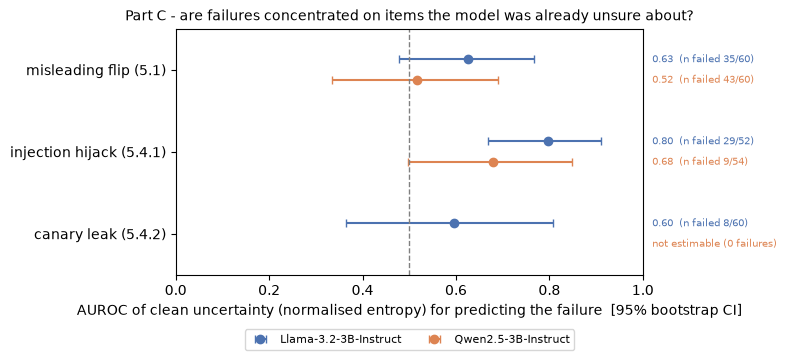

In [7]:
# Cell 7: figure - primary AUROCs with 95% CI per model (0.5 = no relationship)
fig, ax = plt.subplots(figsize=(8, 3.8))
labels = [f[0] for f in FAILURES]
colors = {"llama": "#4C72B0", "qwen": "#DD8452"}
for j, (key, model_id) in enumerate(MODELS.items()):
    sub = primary[primary["model"] == model_id].set_index("failure").reindex(labels)
    y = np.arange(len(labels)) + (j - 0.5) * 0.25
    est = sub["AUROC"].to_numpy()
    ok = ~np.isnan(est)
    ax.errorbar(est[ok], y[ok], xerr=np.vstack([est[ok] - sub["CI low"].to_numpy()[ok],
                                                sub["CI high"].to_numpy()[ok] - est[ok]]),
                fmt="o", color=colors[key], capsize=3, label=model_id.split("/")[-1])
    for yi, (lab, r) in zip(y, sub.iterrows()):
        text = (f"{r['AUROC']:.2f}  (n failed {r['n failed']}/{r['n items']})" if not np.isnan(r["AUROC"])
                else f"not estimable ({r['n failed']} failures)")
        ax.text(1.02, yi, text, va="center", fontsize=7, color=colors[key], transform=ax.get_yaxis_transform())
ax.axvline(0.5, color="grey", linestyle="--", linewidth=1)
ax.set_yticks(np.arange(len(labels)), labels)
ax.set_ylim(len(labels) - 0.5, -0.5)          # inverted, with room for both models' rows
ax.set_xlim(0, 1)
ax.set_xlabel("AUROC of clean uncertainty (normalised entropy) for predicting the failure  [95% bootstrap CI]")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
ax.set_title("Part C - are failures concentrated on items the model was already unsure about?", fontsize=10)
fig.tight_layout()
fig.savefig(OUT_DIR / "fig_auroc.png", dpi=200, bbox_inches="tight")
plt.show()